<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/08_Lab_CNN_Ising_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes neuronales convolucionales

In [56]:
import numpy as np
import matplotlib.pylab as plt
import sympy as sp
import scipy as sc
#import tensorflow as tf
#https://setosa.io/ev/image-kernels/

In [57]:
12*1+2*1*1+12*-1+-1+-1

0

# Convolución
![convolucion](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/convolution.png?raw=true)




1. Dada una imagen  :

```
M = array([[10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0]])
```
Apliquemos un filtro
```
filter = array([[ 1,  0, -1],
       [ 1,  0, -1],
       [ 1,  0, -1]])
```

Y construyamos la operacion de convolucion

Results = M * Filter

```
Results = array([[ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0]])
  ```


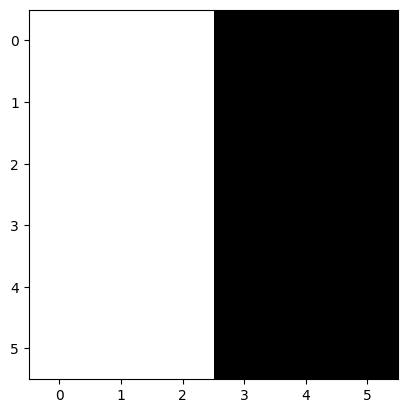

In [58]:
#Construyamos una imagen de negros y blancos
V = np.array([10,10,10,0,0,0])
Img = np.tile(V,6).reshape(6,6)
Img
plt.imshow(Img, cmap="gray")

 Detectemos los bordes con un filtro vertical
```
A = [[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]
 ```

[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


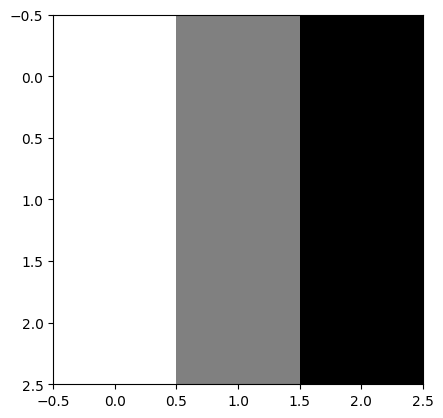

In [59]:
F = np.array([1,0,-1])
filter = np.tile(F,3).reshape(3,3)
print(filter)
plt.imshow(filter, cmap="gray")


La operación de convolución, permite construir una nueva matrix en la que se puede indentificar los bordes.

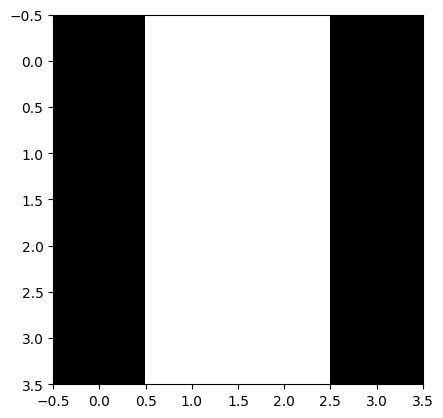

In [60]:
from scipy import signal
#new_img = np.convolve(Img, filter)
new_img = signal.convolve2d(Img, filter,mode="valid")

abs(new_img)
plt.figure()
plt.imshow(abs(new_img), cmap="gray")
plt.show()


In [61]:
new_img

array([[  0, -30, -30,   0],
       [  0, -30, -30,   0],
       [  0, -30, -30,   0],
       [  0, -30, -30,   0]])

In [62]:
# in_img  = tf.constant(Img)
# filter_img  = tf.constant(filter)
# tf.nn.conv2d(in_img, filter_img,padding='VALID')

Apliquemos un filtro horizontal

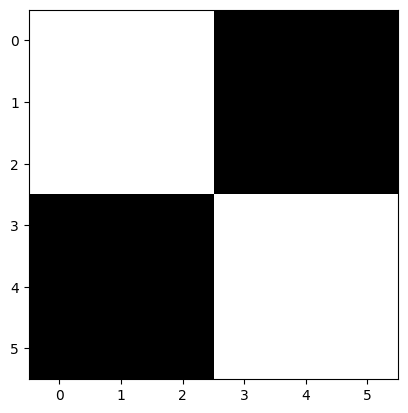

In [63]:
M = np.array([[10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [0, 0, 0,  10,  10,  10],
       [0, 0, 0,  10,  10,  10],
       [0, 0, 0,  10,  10,  10]])

plt.imshow(M, cmap="gray")

In [64]:
sp.Matrix(M)

Matrix([
[10, 10, 10,  0,  0,  0],
[10, 10, 10,  0,  0,  0],
[10, 10, 10,  0,  0,  0],
[ 0,  0,  0, 10, 10, 10],
[ 0,  0,  0, 10, 10, 10],
[ 0,  0,  0, 10, 10, 10]])

Matrix([
[ 1,  1,  1],
[ 0,  0,  0],
[-1, -1, -1]])

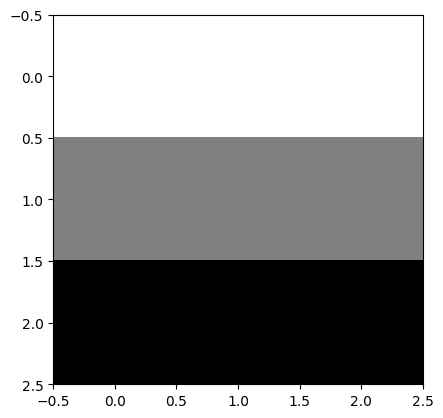

In [65]:
F = np.array([1,0,-1])
filter = np.tile(F,3).reshape(3,3)
filter=filter.T
#print(filter)
plt.imshow(filter, cmap="gray")
sp.Matrix(filter)

[[  0   0   0   0]
 [-30 -10  10  30]
 [-30 -10  10  30]
 [  0   0   0   0]]


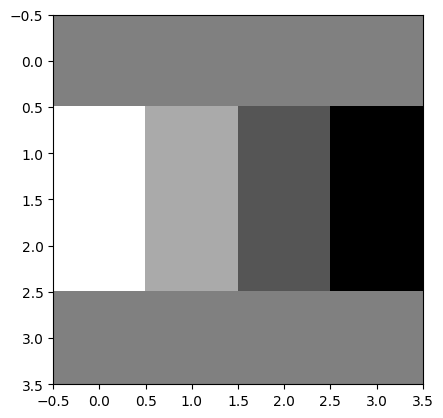

Matrix([
[ 0,  0,   0,   0],
[30, 10, -10, -30],
[30, 10, -10, -30],
[ 0,  0,   0,   0]])

In [66]:
new_img = signal.convolve2d(M,filter,mode="valid")
print(new_img)
plt.figure()
plt.imshow(-new_img, cmap="gray")
plt.show()
sp.Matrix(-new_img)


Existen otro tipo de filtros que pueden ser empleados.

- [Sobel filter](https://en.wikipedia.org/wiki/Sobel_operator)
  ```
  filter = array([[ 1,  0, -1],
       [ 2,  0, -2],
       [ 1,  0, -1]])
```
- Scharr Filter
```
filter = array([[ 3,  0, -3],
       [ 10,  0, -10],
       [ 3,  0, -3]])
```

¿Cómo elegir los parametros del filtro para detectar otro tipo de bordes?
```
filter = array([[ w1,  w2, w3],
     [ w4,  w5, w6],
     [ w7,  w8, w9]])
```

# Padding

El padding permite que la imagen resultante, sea del mismo tamaño que la original. Dada una matrix $n \times n$ asociada a una imagen y aplicada un filtro de rango $f\times f$ la operación después de la convolución es de rango $(n-f+1) \times (n-f+1)$.

Para garantizar que se tenga una imagen con el mismo tamaño de la original se aplica el padding



Para un padding de 1,tenemos entonces la siguientes dimensiones:

###  input = (n)x(n)


![input](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/input.png?raw=true)


### filter = fxf

![filter](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/filter.png?raw=true)



###  Output = (n-f+1)x(n-f+1)


![Output](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/output.png?raw=true)

--------------------------------------------------------------

 ### input con padding = (n+2p)x(n+2p)
![padding](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/padding.png?raw=true)



### filter = fxf

![filter](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/filter.png?raw=true)


###  Output = (n+2p-f+1)x(n+2p-f+1)




## Valid Padding

  - nxn * fxf ---> n-f+1

## Same Padding
The output size is the same that the input size

- n+2pxn+2p * fxf ---> n-f+1+2p x n-f+1+2p


# Stride

Salto entre valores de la imagen para hacer la convolución, en la siguiente imagen se muestra un stride de s=2.

Input : 6x6 = nxn

Filter : 3x3 = fxf

Results = Input * Filter

Results: (6-3)/2--->2x2

$\left[ \frac{n+2*p-f}{s}+1 \right] \times \left[ \frac{n+2*p-f}{s}+1 \right]$

[] operation floor


![stride](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/stride.png?raw=true)




# Convolución sobre todo el volumen:

![volumen](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/rgb_volume.png?raw=true)


## Multiples filtros sobre el volumen:


![multiples filtros](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/rgb_two_filter.png?raw=true)

Input= nxnxnc

Filter= fxfxnc

Output= n-f+1 x  n-f+1  x n'c

nc= numero de canales

n'c= el numero de filtros





REf: https://towardsdatascience.com/beginners-guide-to-understanding-convolutional-neural-networks-ae9ed58bb17d


# Clasificación de fases del modelo de Ising con una red convolucional (Keras)

Este laboratorio es análogo a `07_Lab_NN_IsingV2` (donde construimos un MLP), pero ahora usamos **Keras** — una API de más alto nivel — y una **red convolucional (CNN)** en lugar de un perceptrón multicapa.

Vamos a:

1. Hacer una introducción breve a Keras.
2. Cargar las configuraciones de espines del modelo de Ising (`Datos/ising_dataset.npz`).
3. Construir y entrenar una CNN simple que clasifique cada configuración como fase **ordenada** o **desordenada**.
4. Evaluarla sobre un barrido fino de temperaturas (`Datos/temperatura_critica.npz`) para **estimar la temperatura crítica** $T_c$ a partir de dónde la red cambia de opinión.
5. Bonus: usar la misma red, sin reentrenar, sobre configuraciones de **otro tamaño de red** ($L=20$, `Datos/temperatura_critica20.npz`).

## 0. ¿Qué es Keras?

**Keras** es una API de alto nivel para construir y entrenar redes neuronales. Desde la versión 3, Keras es *multi-backend*: el mismo código (`keras.layers`, `keras.Model`, `.compile()`, `.fit()`, ...) puede ejecutarse sobre **TensorFlow**, **JAX** o **PyTorch** como motor de cómputo. El backend se elige con la variable de entorno `KERAS_BACKEND` **antes** de importar `keras`; el resto del notebook no depende de cuál se use.

Comparado con lo que se hace  "a mano" en PyTorch, Keras encapsula el ciclo de entrenamiento:

| PyTorch (manual)                                              | Keras (equivalente)                    |
|---|---|
| Definir `Dataset` + `DataLoader`                               | Pasar arreglos de NumPy directamente a `.fit()` |
| Escribir el bucle `for epoch ... for batch ...`                | `model.fit(X, y, epochs=..., batch_size=...)` |
| `loss.backward()`, `optimizer.step()`, `optimizer.zero_grad()` | Ocurre internamente en `.fit()`        |
| Guardar el mejor modelo con un `if val_loss < best_val_loss`   | Callback `keras.callbacks.ModelCheckpoint` |
| `model.eval()` + `torch.no_grad()` + bucle manual              | `model.evaluate(X, y)` / `model.predict(X)` |

Un modelo en Keras se arma apilando **capas** (`keras.layers`) dentro de un `keras.Sequential` (o la API funcional para arquitecturas más complejas), se **compila** indicando optimizador, función de pérdida y métricas, y se **entrena** con `.fit()`.

In [67]:
import os
os.environ.setdefault("KERAS_BACKEND", "jax")  # TensorFlow, JAX o PyTorch: el código de Keras no cambia

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())

Keras: 3.13.2
Backend: jax


## 1. Datos: configuraciones de espines del modelo de Ising

Reutilizamos el dataset generado en `07_Lab_NN_IsingV2` (ver `07_bDatos_Ising.ipynb` para el detalle de cómo se generó). Cada configuración es una matriz $L\times L$ de espines $\pm 1$, etiquetada según su temperatura respecto a $T_c$:

| | fase **ordenada** (`y = 0`) | fase **desordenada** (`y = 1`) |
|---|---|---|
| temperatura | $T < T_c$ | $T > T_c$ |
| aspecto | un dominio grande domina la red | "ruido", sin dominios |

`ising_dataset.npz` **excluye** una banda alrededor de $T_c$ a propósito, para que las etiquetas sean inequívocas durante el entrenamiento.

In [68]:
#datos = np.load("Datos/ising_dataset.npz", allow_pickle=False)
datos = np.load("ising_dataset.npz", allow_pickle=False)

X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]
Tc_onsager = float(datos["Tc"])
L = int(datos["L"])

print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Temperaturas:", np.unique(T))
print("Realizaciones:", np.unique(realizacion))
print(f"L = {L}   Tc (Onsager) = {Tc_onsager:.4f}")

X: (1600, 16, 16) int8
y: (1600,) int8
Temperaturas: [1.2   1.375 1.55  1.725 1.9   2.6   2.825 3.05  3.275 3.5  ]
Realizaciones: [0 1 2 3]
L = 16   Tc (Onsager) = 2.2692


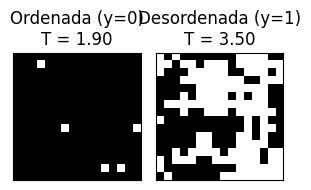

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(3, 3))

idx_ordenada = np.where(y == 0)[0][0]
idx_desordenada = np.where(y == 1)[0][0]

for ax, idx, titulo in zip(
    axes,
    [idx_ordenada, idx_desordenada],
    [f"Ordenada (y=0)\nT = {T[idx_ordenada]:.2f}", f"Desordenada (y=1)\nT = {T[idx_desordenada]:.2f}"],
):
    ax.imshow(X[idx], cmap="gray", vmin=-1, vmax=1)
    ax.set_title(titulo)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

## 2. Preparación de los datos para Keras

Igual que en el notebook de PyTorch, usamos el campo `realizacion` (cadena de Monte Carlo independiente) para separar train/val/test, evitando que configuraciones muy correlacionadas de una misma cadena aparezcan en más de un conjunto:

- `realizacion` 0 y 1 → entrenamiento
- `realizacion` 2 → validación
- `realizacion` 3 → test

A diferencia del MLP (que aplanaba cada configuración a un vector de 256 valores), una CNN espera imágenes con forma `(alto, ancho, canales)`. Como tenemos un solo canal (el espín), reformamos cada configuración a `(L, L, 1)`. No hace falta convertir nada a tensores de PyTorch ni armar `DataLoader`s: Keras trabaja directamente con arreglos de NumPy.

In [70]:
mask_train = np.isin(realizacion, [0, 1])
mask_val = realizacion == 2
mask_test = realizacion == 3

def preparar(mask):
    X_ = X[mask].astype("float32").reshape(-1, L, L, 1)
    y_ = y[mask].astype("float32")
    T_ = T[mask]
    return X_, y_, T_

X_train, y_train, T_train = preparar(mask_train)
X_val, y_val, T_val = preparar(mask_val)
X_test, y_test, T_test = preparar(mask_test)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

Train: (800, 16, 16, 1) (800,)
Val:   (400, 16, 16, 1) (400,)
Test:  (400, 16, 16, 1) (400,)


## 3. Arquitectura: red convolucional simple

Una CNN es una elección natural para este problema: la fase de una configuración es una propiedad **estadística y global** (¿hay dominios grandes o no?), no depende de *dónde* aparezcan los dominios. Los filtros convolucionales detectan patrones locales (espines alineados con sus vecinos) **sin importar la posición**, exactamente la invariancia que necesitamos.

Arquitectura (deliberadamente simple):

- `Conv2D(8, 3x3) + ReLU` — detecta patrones locales de alineación.
- `MaxPooling2D(2x2)` — reduce la resolución espacial.
- `Conv2D(16, 3x3) + ReLU` — combina patrones locales en patrones un poco más grandes.
- `GlobalAveragePooling2D` — en vez de aplanar (`Flatten`) y usar una capa densa grande, promediamos cada mapa de activación sobre todo el espacio. Esto produce un vector de tamaño fijo **sin importar el tamaño $L\times L$ de la entrada**: la misma red podrá evaluarse más adelante sobre configuraciones de otro tamaño de red, algo que el MLP (con su entrada aplanada de tamaño fijo) no puede hacer.
- `Dense(16) + ReLU` y `Dense(1) + sigmoide` — combinan las características globales en una probabilidad de fase desordenada.

Para permitir tamaños de entrada variables declaramos `Input(shape=(None, None, 1))`.

In [71]:
keras.utils.set_random_seed(42)

model = keras.Sequential(
    [
        keras.Input(shape=(None, None, 1)),
        layers.Conv2D(8, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="ising_cnn",
)

model.summary()

Model: "ising_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, None, None, 8)  │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, None, None, 8)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, None, None, 16) │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Compilación y entrenamiento

`compile()` fija el optimizador, la función de pérdida y las métricas a reportar. Como la última capa ya tiene activación sigmoide (produce una probabilidad), usamos `binary_crossentropy` directamente (en PyTorch usamos `BCEWithLogitsLoss` porque la red devolvía *logits*, no probabilidades).

El callback `ModelCheckpoint` guarda automáticamente los pesos con menor `val_loss`, reemplazando el bloque manual `if val_loss < best_val_loss: ...` del notebook de PyTorch.

In [72]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "best_ising_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
)

historia = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[checkpoint],
    verbose=2,
)

Epoch 1/20
25/25 - 6s - 257ms/step - accuracy: 0.8487 - loss: 0.5898 - val_accuracy: 1.0000 - val_loss: 0.4615
Epoch 2/20
25/25 - 1s - 22ms/step - accuracy: 1.0000 - loss: 0.3420 - val_accuracy: 0.9975 - val_loss: 0.2166
Epoch 3/20
25/25 - 1s - 22ms/step - accuracy: 1.0000 - loss: 0.1371 - val_accuracy: 1.0000 - val_loss: 0.0765
Epoch 4/20
25/25 - 1s - 21ms/step - accuracy: 1.0000 - loss: 0.0512 - val_accuracy: 1.0000 - val_loss: 0.0335
Epoch 5/20
25/25 - 0s - 15ms/step - accuracy: 1.0000 - loss: 0.0246 - val_accuracy: 1.0000 - val_loss: 0.0195
Epoch 6/20
25/25 - 1s - 24ms/step - accuracy: 1.0000 - loss: 0.0160 - val_accuracy: 0.9975 - val_loss: 0.0144
Epoch 7/20
25/25 - 1s - 39ms/step - accuracy: 1.0000 - loss: 0.0108 - val_accuracy: 1.0000 - val_loss: 0.0103
Epoch 8/20
25/25 - 1s - 40ms/step - accuracy: 1.0000 - loss: 0.0082 - val_accuracy: 1.0000 - val_loss: 0.0087
Epoch 9/20
25/25 - 1s - 36ms/step - accuracy: 1.0000 - loss: 0.0068 - val_accuracy: 1.0000 - val_loss: 0.0074
Epoch 10/

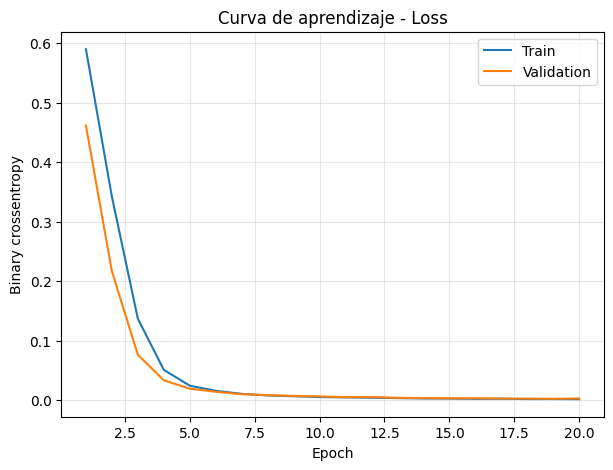

In [73]:
epochs_range = range(1, len(historia.history["loss"]) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs_range, historia.history["loss"], label="Train")
plt.plot(epochs_range, historia.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.title("Curva de aprendizaje - Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

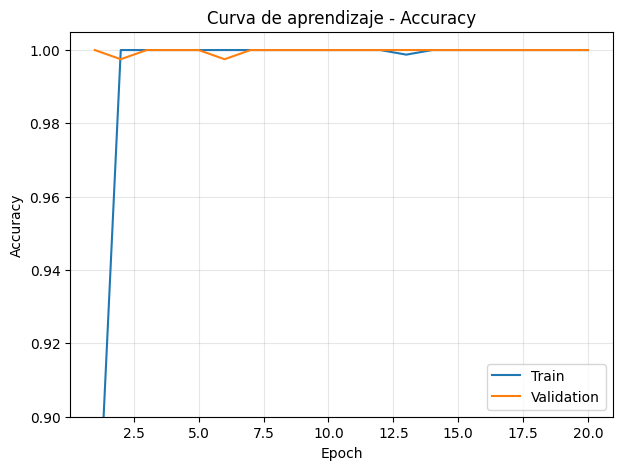

In [74]:
plt.figure(figsize=(7, 5))
plt.plot(epochs_range, historia.history["accuracy"], label="Train")
plt.plot(epochs_range, historia.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Curva de aprendizaje - Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0.9, 1.005)
plt.show()

## 5. Evaluación en el conjunto de test

In [75]:
model = keras.models.load_model("best_ising_cnn.keras")

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.5f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss:     0.00321
Test accuracy: 1.0000


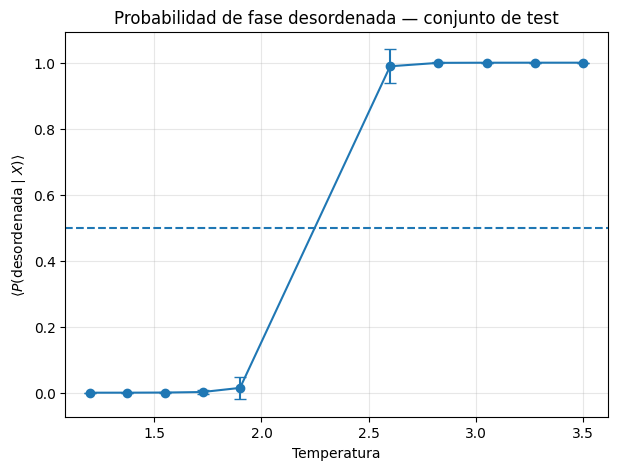

In [76]:
probs_test = model.predict(X_test, verbose=0).ravel()

unique_T_test = np.unique(T_test)
mean_p, std_p = [], []
for temp in unique_T_test:
    mask = T_test == temp
    mean_p.append(probs_test[mask].mean())
    std_p.append(probs_test[mask].std())
mean_p, std_p = np.array(mean_p), np.array(std_p)

plt.figure(figsize=(7, 5))
plt.errorbar(unique_T_test, mean_p, yerr=std_p, fmt="o-", capsize=4)
plt.axhline(0.5, linestyle="--")
plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada} \mid X)\rangle$")
plt.title("Probabilidad de fase desordenada — conjunto de test")
plt.grid(alpha=0.3)
plt.show()

## 6. Barrido cerca de la temperatura crítica

`ising_dataset.npz` deja fuera a propósito una banda alrededor de $T_c$. `temperatura_critica.npz` es el conjunto contrario: un barrido fino que **sí incluye** la zona crítica, con varias realizaciones independientes. Aquí no hay etiqueta de entrenamiento confiable — la idea es que, si la red aprendió a reconocer fases, su probabilidad promedio $\langle P(\mathrm{desordenada}\mid T)\rangle$ pase de 0 a 1 alrededor de la verdadera $T_c$, y podamos **estimar $T_c$ como el punto donde esa curva cruza 0.5**.

In [77]:
#datos_tc = np.load("Datos/temperatura_critica.npz", allow_pickle=False)
datos_tc = np.load("temperatura_critica.npz", allow_pickle=False)
X_tc = datos_tc["X"].astype("float32").reshape(-1, L, L, 1)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]

print("X_tc:", X_tc.shape)
print("Temperaturas:", np.unique(T_tc))
print("Realizaciones:", np.unique(realizacion_tc))

X_tc: (6200, 16, 16, 1)
Temperaturas: [1.6   1.7   1.8   1.9   2.    2.05  2.075 2.1   2.125 2.15  2.175 2.2
 2.225 2.25  2.275 2.3   2.325 2.35  2.375 2.4   2.425 2.45  2.475 2.5
 2.6   2.7   2.8   2.9   3.    3.1   3.2  ]
Realizaciones: [0 1 2 3]


In [78]:
probs_tc = model.predict(X_tc, verbose=0).ravel()
pred_tc = (probs_tc >= 0.5).astype(int)

df = pd.DataFrame({
    "T": T_tc,
    "realizacion": realizacion_tc,
    "probabilidad": probs_tc,
    "prediccion": pred_tc,
})

resumen = (
    df.groupby(["realizacion", "T"])
      .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"), N=("prediccion", "size"))
      .reset_index()
)

resumen.head(10)

,realizacion,T,prob_media,prob_std,N
0,0,1.600,0.000435,0.000341,50
1,0,1.700,0.001301,0.002158,50
2,0,1.800,0.002337,0.004612,50
3,0,1.900,0.004350,0.006657,50
4,0,2.000,0.021877,0.047564,50
5,0,2.050,0.113461,0.192206,50
6,0,2.075,0.077053,0.126211,50
7,0,2.100,0.075800,0.137167,50
8,0,2.125,0.193400,0.302327,50
9,0,2.150,0.241184,0.313026,50


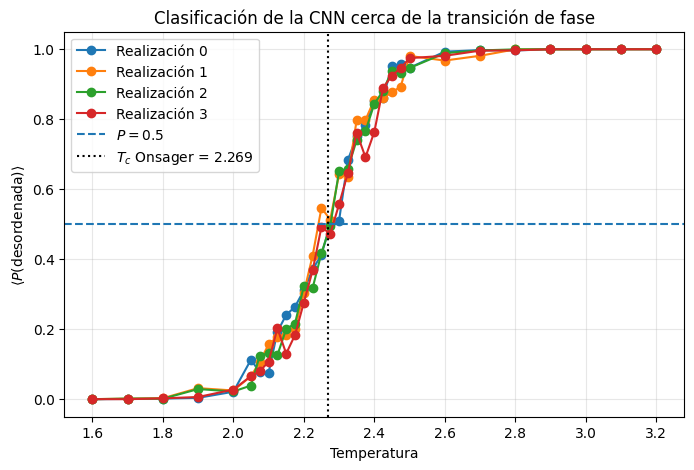

In [79]:
plt.figure(figsize=(8, 5))

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r]
    plt.plot(datos_r["T"], datos_r["prob_media"], "o-", label=f"Realización {r}")

plt.axhline(0.5, linestyle="--", label=r"$P=0.5$")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada})\rangle$")
plt.title("Clasificación de la CNN cerca de la transición de fase")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [80]:
Tc_estimadas = []

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r].sort_values("T")
    temps = datos_r["T"].to_numpy()
    probs = datos_r["prob_media"].to_numpy()

    for i in range(len(temps) - 1):
        p1, p2 = probs[i], probs[i + 1]
        if p1 <= 0.5 <= p2:
            T1, T2 = temps[i], temps[i + 1]
            Tc_r = T1 + (0.5 - p1) * (T2 - T1) / (p2 - p1)  # interpolación lineal
            Tc_estimadas.append(Tc_r)
            print(f"Realización {r}: Tc_CNN = {Tc_r:.4f}")
            break

Tc_estimadas = np.array(Tc_estimadas)
Tc_mean = Tc_estimadas.mean()
Tc_std = Tc_estimadas.std(ddof=1)

print()
print(f"Tc_CNN promedio = {Tc_mean:.4f} +/- {Tc_std:.4f}")
print(f"Tc Onsager      = {Tc_onsager:.4f}")

Realización 0: Tc_CNN = 2.2759
Realización 1: Tc_CNN = 2.2414
Realización 2: Tc_CNN = 2.2757
Realización 3: Tc_CNN = 2.2832

Tc_CNN promedio = 2.2691 +/- 0.0188
Tc Onsager      = 2.2692


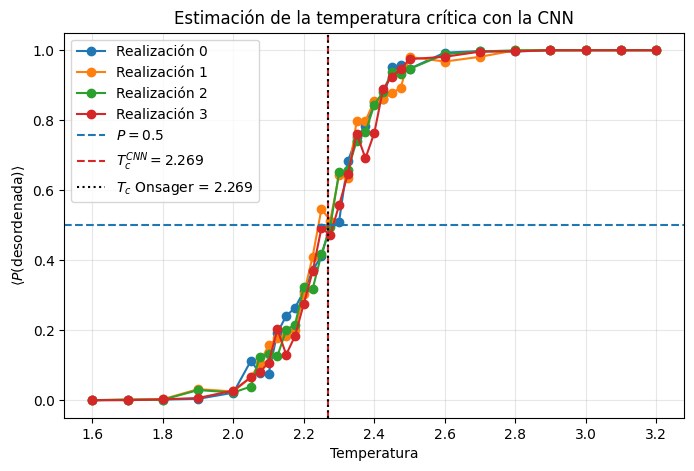

In [81]:
plt.figure(figsize=(8, 5))

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r]
    plt.plot(datos_r["T"], datos_r["prob_media"], "o-", label=f"Realización {r}")

plt.axhline(0.5, linestyle="--", label=r"$P=0.5$")
plt.axvline(Tc_mean, linestyle="--", color="C3", label=fr"$T_c^{{CNN}} = {Tc_mean:.3f}$")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada})\rangle$")
plt.title("Estimación de la temperatura crítica con la CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Bonus: generalización a otro tamaño de red ($L=20$)

`GlobalAveragePooling2D` hace que la red no tenga ningún peso atado a un tamaño de entrada específico. Podemos entonces tomar exactamente el mismo modelo, **sin reentrenar**, y evaluarlo sobre `temperatura_critica20.npz` (configuraciones $20\times 20$, con la misma $T_c$ física). Con un MLP de entrada aplanada esto sería imposible sin cambiar la arquitectura.

In [82]:
#datos_tc20 = np.load("Datos/temperatura_critica20.npz", allow_pickle=False)
datos_tc20 = np.load("temperatura_critica20.npz", allow_pickle=False)
L20 = int(datos_tc20["L"])

X_tc20 = datos_tc20["X"].astype("float32").reshape(-1, L20, L20, 1)
T_tc20 = datos_tc20["T"]
realizacion_tc20 = datos_tc20["realizacion"]

print(f"L = {L20}   X_tc20: {X_tc20.shape}")

probs_tc20 = model.predict(X_tc20, verbose=0).ravel()

df20 = pd.DataFrame({
    "T": T_tc20,
    "realizacion": realizacion_tc20,
    "probabilidad": probs_tc20,
})

resumen20 = (
    df20.groupby("T")
        .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"))
        .reset_index()
)

L = 20   X_tc20: (6200, 20, 20, 1)


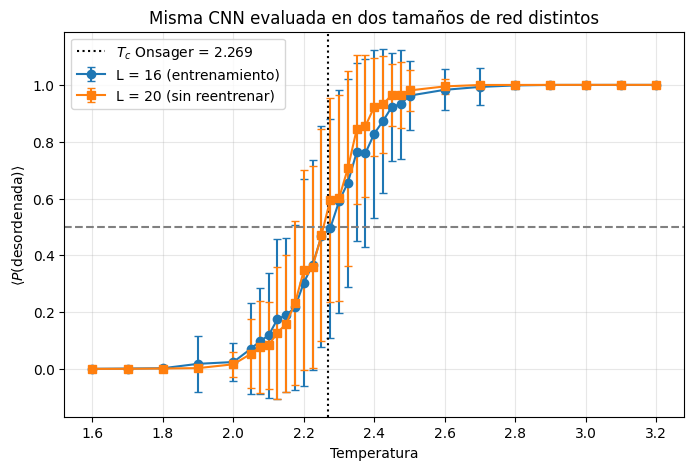

In [83]:
resumen16 = (
    df.groupby("T")
      .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"))
      .reset_index()
)

plt.figure(figsize=(8, 5))

plt.errorbar(resumen16["T"], resumen16["prob_media"], yerr=resumen16["prob_std"],
             fmt="o-", capsize=3, label=f"L = {L} (entrenamiento)")
plt.errorbar(resumen20["T"], resumen20["prob_media"], yerr=resumen20["prob_std"],
             fmt="s-", capsize=3, label=f"L = {L20} (sin reentrenar)")

plt.axhline(0.5, linestyle="--", color="gray")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada})\rangle$")
plt.title("Misma CNN evaluada en dos tamaños de red distintos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Para una red más grande ($L=20$) se espera que la transición se vea **más abrupta** (más cercana al límite termodinámico, donde la transición de fase es discontinua), mientras que en $L=16$ el efecto de tamaño finito la suaviza un poco. Aun así, la misma CNN — sin ver un solo ejemplo de $L=20$ durante el entrenamiento — debería ubicar el cruce cerca de $T_c$.


- Keras permite construir y entrenar la misma clase de clasificador que hicimos con PyTorch en muchas menos líneas: no hay bucle de entrenamiento manual, `DataLoader` ni manejo explícito del dispositivo.
- Una CNN simple (dos capas convolucionales + *global average pooling*) alcanza una exactitud muy alta separando fase ordenada vs. desordenada lejos de $T_c$.
- Evaluando la red sobre el barrido fino de temperaturas, la probabilidad de fase desordenada cruza $0.5$ muy cerca de la $T_c$ de Onsager, sin que la red haya visto nunca esa temperatura durante el entrenamiento.
- Gracias a `GlobalAveragePooling2D`, la arquitectura no depende del tamaño $L\times L$ de la red de espines, lo que permite reutilizar el mismo modelo entrenado sobre configuraciones de otro tamaño — algo que un MLP con entrada aplanada no puede hacer sin cambiar de arquitectura.

# Laboratorio: interpreta la red, no solo confíes en ella

La CNN clasifica fases con exactitud casi perfecta y ubica $T_c$ con buena precisión. Eso no basta: una red puede acertar por razones equivocadas (un atajo espurio en los datos, por ejemplo). Antes de dar el resultado por bueno, ábrela:

- Estudia los kernels de la primera capa convolucional. ¿Qué patrón detecta cada uno? Compáralos con un kernel de "vecinos cercanos" (como el acoplamiento del Hamiltoniano de Ising) y con un kernel de "promedio local" (un detector de magnetización). ¿Se parece alguno a estos kernels físicos, o la red encontró otra cosa?


- Analiza los mapas de activación de esos filtros sobre una configuración ordenada y una desordenada. ¿La diferencia visual que ves coincide con lo que dirías tú, a ojo, si miraras las dos configuraciones sin saber la respuesta?


- Mide qué tan sensible es la red a voltear un solo espín, lejos de $T_c$ y cerca de $T_c$. ¿Dónde es más sensible? ¿Se te ocurre una razón física para eso?

$$S(x) = \frac{1}{L^2}\sum_{i=1}^{L^2} \big|\Delta P_i(x)\big|, \qquad \Delta P_i(x) = P(\text{config. con } s_i \text{ volteado}) - P(x)$$


- Verifica si el logit ($z = Wx+b$) final es, en el fondo, una función de la magnetización. Grafica el logit contra $|m(x)|$, antes y después de entrenar. ¿La red "redescubrió" el parámetro de orden por su cuenta, o el resultado depende de trucos de la arquitectura?

#MI PARTE DEL LABORATORIO

### 1) Estudia los kernels de la primera capa convolucional. ¿Qué patrón detecta cada uno? Compáralos con un kernel de "vecinos cercanos" (como el acoplamiento del Hamiltoniano de Ising) y con un kernel de "promedio local" (un detector de magnetización). ¿Se parece alguno a estos kernels físicos, o la red encontró otra cosa?

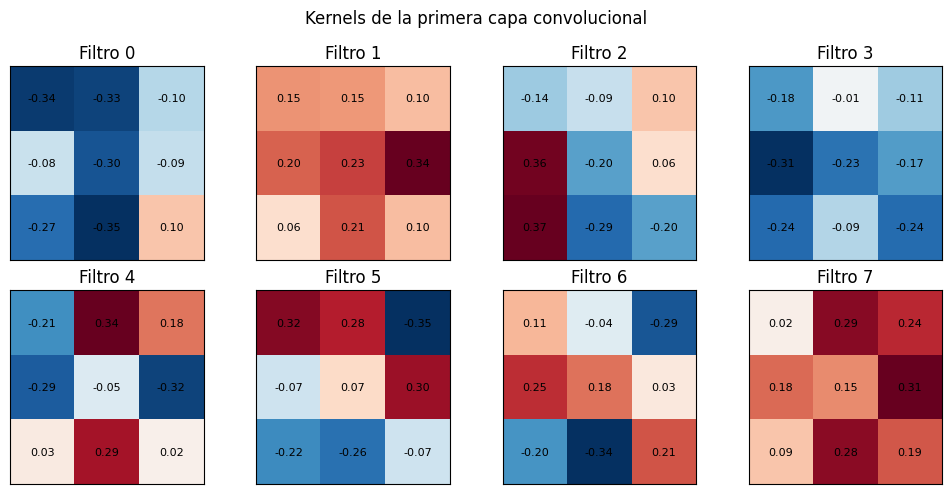

  Filtro  Coseno con promedio  Coseno con vecinos                       Tipo
Filtro 0               -0.795              -0.573  otra cosa (borde / mixto)
Filtro 1                0.907               0.790 parecido al promedio local
Filtro 2               -0.009               0.033  otra cosa (borde / mixto)
Filtro 3               -0.896              -0.497 parecido al promedio local
Filtro 4               -0.002               0.017  otra cosa (borde / mixto)
Filtro 5               -0.007               0.166  otra cosa (borde / mixto)
Filtro 6               -0.038              -0.074  otra cosa (borde / mixto)
Filtro 7                0.902               0.824 parecido al promedio local


In [84]:
# 1. Extraer y graficar los 8 kernels de la primera capa
weights, biases = model.layers[0].get_weights()   # forma (3, 3, 1, 8)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    k = weights[:, :, 0, i]
    v = np.abs(k).max()
    ax.imshow(k, cmap="RdBu_r", vmin=-v, vmax=v)
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{k[r, c]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"Filtro {i}")
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Kernels de la primera capa convolucional")
plt.tight_layout()
plt.show()

# 2. Kernels físicos de referencia
k_promedio = np.ones((3, 3)) / 9            # promedio local (magnetización)
k_vecinos = np.array([[0, 1, 0],
                      [1, 0, 1],
                      [0, 1, 0]]) / 4       # suma de los 4 vecinos (acoplamiento de Ising)

def coseno(a, b):
    a, b = a.ravel(), b.ravel()
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# 3. Comparar cada filtro con las referencias
filas = []
for i in range(8):
    k = weights[:, :, 0, i]
    s_prom = coseno(k, k_promedio)
    s_vec = coseno(k, k_vecinos)
    if abs(s_prom) > 0.8:
        tipo = "parecido al promedio local"
    elif abs(s_vec) > 0.8:
        tipo = "parecido a vecinos"
    else:
        tipo = "otra cosa (borde / mixto)"
    filas.append([f"Filtro {i}", round(s_prom, 3), round(s_vec, 3), tipo])

tabla = pd.DataFrame(filas, columns=["Filtro", "Coseno con promedio", "Coseno con vecinos", "Tipo"])
print(tabla.to_string(index=False))

### Conclusión: kernels de la primera capa convolucional

Al comparar los 8 filtros con el kernel de promedio local (coseno), aparecen dos grupos claros:

- Filtros 0, 1, 3 y 7: tienen un coseno alto en valor absoluto con el promedio local (entre 0.80 y 0.91), es decir, son casi uniformes y suman los espines de la vecindad 3×3. Se comportan como detectores de magnetización local. Los filtros 1 y 7 tienen signo positivo y los filtros 0 y 3 signo negativo, lo que es coherente con la simetría ±1 de la fase ordenada (magnetización positiva o negativa). El filtro 0 (−0.795) quedó como "otra cosa" solo por el umbral de 0.8 y en la práctica pertenece a este grupo.
- Filtros 2, 4, 5 y 6: tienen un coseno cercano a cero con el promedio local (|coseno| < 0.04) y también con el kernel de vecinos (|coseno| ≤ 0.17). No miden magnetización ni replican el acoplamiento de Ising; probablemente detectan diferencias entre píxeles vecinos (bordes o otras cosas que no vemos a simple vista), señal de desorden !! . Esto es solo una idea, habria que estudiarlo a profundidad para dar un veredicto.

Los filtros 1, 3 y 7 también muestran un coseno alto con el kernel de vecinos (0.5 a 0.8), pero esto no indica que la red haya aprendido el acoplamiento de Ising: ambos kernels de referencia son positivos y casi uniformes, así que se parecen entre sí, y una convolución es lineal en los espines, por lo que no puede calcular productos $s_is_j$ directamente.



### 2) Analiza los mapas de activación de esos filtros sobre una configuración ordenada y una desordenada. ¿La diferencia visual que ves coincide con lo que dirías tú, a ojo, si miraras las dos configuraciones sin saber la respuesta?

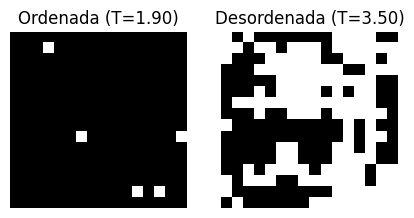

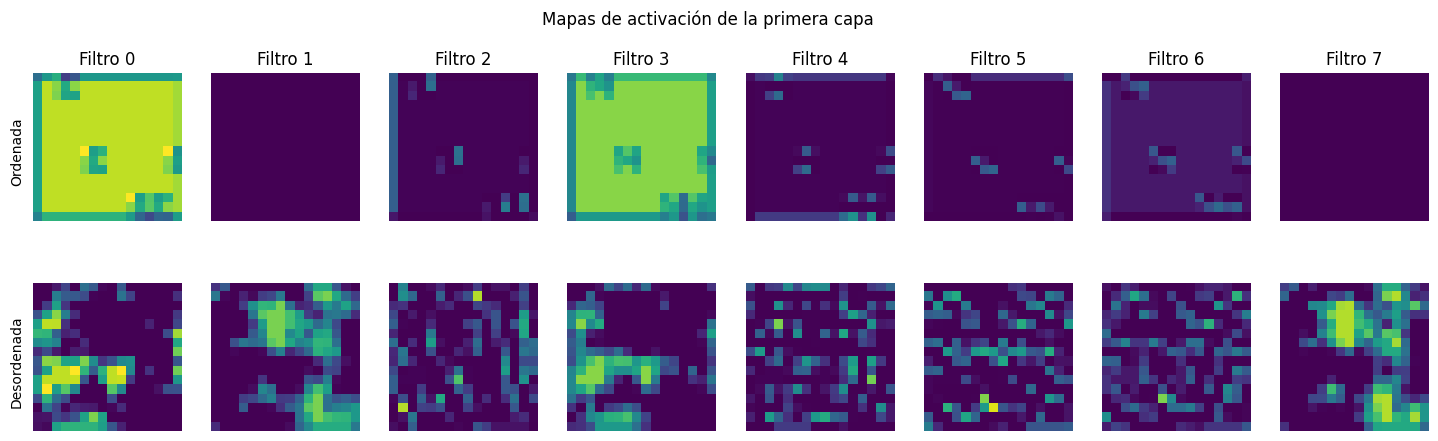

Filtro | std ordenada | std desordenada
  0    |   0.331     |    0.596
  1    |   0.000     |    0.540
  2    |   0.183     |    0.339
  3    |   0.291     |    0.497
  4    |   0.173     |    0.351
  5    |   0.124     |    0.378
  6    |   0.116     |    0.305
  7    |   0.000     |    0.589


In [85]:
# Modelo que devuelve la salida de la primera capa convolucional (Conv + ReLU)
act_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)

# Una configuración ordenada (y=0) y una desordenada (y=1)
i_ord = np.where(y == 0)[0][0]
i_des = np.where(y == 1)[0][0]

conf_ord = X[i_ord].astype("float32").reshape(1, L, L, 1)
conf_des = X[i_des].astype("float32").reshape(1, L, L, 1)

act_ord = act_model.predict(conf_ord, verbose=0)[0]   # forma (L, L, 8)
act_des = act_model.predict(conf_des, verbose=0)[0]

# Primero las dos configuraciones originales
fig, axs = plt.subplots(1, 2, figsize=(5, 3))
axs[0].imshow(conf_ord[0, :, :, 0], cmap="gray"); axs[0].set_title(f"Ordenada (T={T[i_ord]:.2f})")
axs[1].imshow(conf_des[0, :, :, 0], cmap="gray"); axs[1].set_title(f"Desordenada (T={T[i_des]:.2f})")
for ax in axs: ax.axis("off")
plt.show()

# Luego los 8 mapas de activación: fila de arriba ordenada, fila de abajo desordenada
fig, axs = plt.subplots(2, 8, figsize=(18, 5))
vmax = max(act_ord.max(), act_des.max())   # misma escala para poder comparar
for f in range(8):
    axs[0, f].imshow(act_ord[:, :, f], cmap="viridis", vmin=0, vmax=vmax)
    axs[0, f].set_title(f"Filtro {f}")
    axs[1, f].imshow(act_des[:, :, f], cmap="viridis", vmin=0, vmax=vmax)
    axs[0, f].axis("off"); axs[1, f].axis("off")
axs[0, 0].text(-3, 8, "Ordenada", rotation=90, va="center")
axs[1, 0].text(-3, 8, "Desordenada", rotation=90, va="center")
plt.suptitle("Mapas de activación de la primera capa")
plt.show()

# Un número para resumir: cuánto varía cada mapa en el espacio (std)
print("Filtro | std ordenada | std desordenada")
for f in range(8):
    print(f"  {f}    |   {act_ord[:, :, f].std():.3f}     |    {act_des[:, :, f].std():.3f}")

### Conclusión: mapas de activación

En la configuración "ordenada" (magnetización ≈ −0.96), los mapas son bastante uniformes: la desviación estándar es baja en todos los filtros (entre 0 y 0.33) y mucho menor que en la desordenada. Esto coincide con lo que se ve a ojo, porque casi todos los espines apuntan hacia el mismo lado. Los filtros 1 y 7 tienen std = 0 porque están completamente apagados: son filtros de pesos positivos y, como la magnetización es negativa, la ReLU anula su salida. En cambio, los filtros 0 y 3 (de signo negativo) sí responden, y buena parte de su variación viene de los bordes por el zero-padding.

En la configuración "desordenada" (magnetización ≈ 0.05), todos los filtros tienen mayor variación espacial (std entre 0.31 y 0.60). Los que más varían son los de tipo "promedio local" (0, 1, 3 y 7), porque al haber espines mezclados la magnetización local cambia mucho de una zona a otra y a veces supera el umbral de la ReLU. Los filtros 2, 4, 5 y 6 también aumentan su variación, pero menos.

Entonces, la diferencia que la red usa es la misma que uno vería a simple vista: orden = respuesta uniforme, desorden = respuesta irregular y granular. La red no parece estar usando nada raro. Un detalle técnico: las líneas de activación en los bordes de los mapas no son físicas; vienen del zero-padding, que rompe las condiciones de contorno periódicas del modelo de Ising.

### 3) Mide qué tan sensible es la red a voltear un solo espín, lejos de $T_c$ y cerca de $T_c$. ¿Dónde es más sensible? ¿Se te ocurre una razón física para eso?

$$S(x) = \frac{1}{L^2}\sum_{i=1}^{L^2} \big|\Delta P_i(x)\big|, \qquad \Delta P_i(x) = P(\text{config. con } s_i \text{ volteado}) - P(x)$$


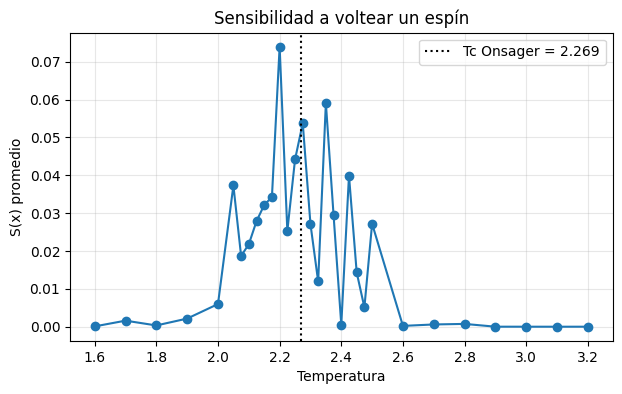

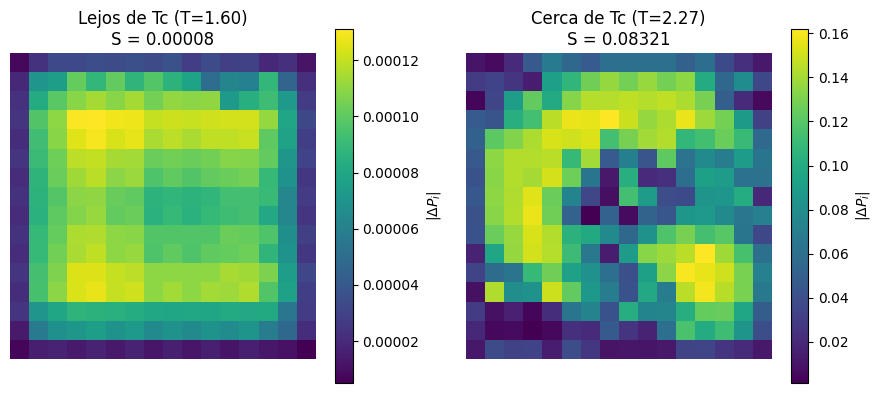

T      | S
1.600  | 0.00009
1.700  | 0.00160
1.800  | 0.00034
1.900  | 0.00215
2.000  | 0.00599
2.050  | 0.03731
2.075  | 0.01870
2.100  | 0.02178
2.125  | 0.02788
2.150  | 0.03216
2.175  | 0.03426
2.200  | 0.07396
2.225  | 0.02529
2.250  | 0.04418
2.275  | 0.05375
2.300  | 0.02713
2.325  | 0.01195
2.350  | 0.05910
2.375  | 0.02947
2.400  | 0.00051
2.425  | 0.03993
2.450  | 0.01434
2.475  | 0.00511
2.500  | 0.02721
2.600  | 0.00022
2.700  | 0.00060
2.800  | 0.00075
2.900  | 0.00001
3.000  | 0.00001
3.100  | 0.00000
3.200  | 0.00001


In [86]:
# S(x): promedio de |P(x con un espín volteado) - P(x)| sobre los L*L espines
def sensibilidad(config):                      # config: (L, L, 1)
    n = L * L
    p0 = model.predict(config[None], verbose=0)[0, 0]

    # n copias de la configuración, y en la copia i volteamos el espín i
    copias = np.repeat(config[None], n, axis=0)
    flat = copias.reshape(n, n)
    flat[np.arange(n), np.arange(n)] *= -1

    p = model.predict(copias, verbose=0).ravel()
    dP = np.abs(p - p0)
    return dP.mean(), dP.reshape(L, L)

# S promedio para cada temperatura del barrido (usamos hasta 5 configuraciones por T)
temps = np.unique(T_tc)
S_medio = []
for t in temps:
    idxs = np.where(T_tc == t)[0][:5]
    S_medio.append(np.mean([sensibilidad(X_tc[i])[0] for i in idxs]))

# Gráfica de S vs T
plt.figure(figsize=(7, 4))
plt.plot(temps, S_medio, "o-")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=f"Tc Onsager = {Tc_onsager:.3f}")
plt.xlabel("Temperatura")
plt.ylabel("S(x) promedio")
plt.title("Sensibilidad a voltear un espín")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Mapas de sensibilidad: una config lejos de Tc (T baja) y una cerca de Tc
i_lejos = np.argmin(T_tc)                               # la T más baja del barrido
i_cerca = np.argmin(np.abs(T_tc - Tc_onsager))          # la más cercana a Tc

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, i, titulo in zip(axs, [i_lejos, i_cerca], ["Lejos de Tc", "Cerca de Tc"]):
    S, mapa = sensibilidad(X_tc[i])
    im = ax.imshow(mapa, cmap="viridis")
    ax.set_title(f"{titulo} (T={T_tc[i]:.2f})\nS = {S:.5f}")
    ax.axis("off")
    plt.colorbar(im, ax=ax, label=r"$|\Delta P_i|$")
plt.tight_layout()
plt.show()

# Los números también, por si la gráfica no es clara
print("T      | S")
for t, s in zip(temps, S_medio):
    print(f"{t:.3f}  | {s:.5f}")

### Conclusión: sensibilidad a voltear un espín

La red es mucho más sensible cerca de Tc que lejos de ella. Lejos de Tc, S es prácticamente cero: por debajo de T = 1.9 es del orden de 10⁻³ o menos (por ejemplo, 0.00009 en T = 1.6) y por encima de T = 2.6 es menor que 10⁻³ (hasta 0.00001 en T = 3.0–3.2). En cambio, en la región entre T ≈ 2.05 y 2.45 la sensibilidad sube a valores de 0.01 a 0.07, con un máximo de 0.074 en T = 2.2, es decir, dos órdenes de magnitud por encima de lo que se ve lejos de la transición.

El máximo queda cerca de la Tc de Onsager (≈ 2.269), un poco por debajo. Sin embargo, la curva no es suave (por ejemplo, S = 0.0005 en T = 2.4 y 0.040 en T = 2.425), porque promedié solo 5 configuraciones por temperatura. Por eso no puedo afirmar que el máximo esté realmente corrido respecto de Tc. Con L = 16 también hay efectos de tamaño finito que ensanchan y desplazan la transición.

La razón física es que cerca de Tc la longitud de correlación y la susceptibilidad divergen: hay fluctuaciones a todas las escalas y el sistema responde mucho a perturbaciones pequeñas. Lejos de Tc, en la fase ordenada (dominios grandes y estables) o en la desordenada (correlaciones muy cortas), un solo espín es irrelevante para el estado global. En la red pasa algo parecido: cerca de Tc la probabilidad está cerca de 0.5, donde la sigmoide tiene su mayor pendiente, y lejos de Tc está saturada cerca de 0 o 1, donde la pendiente es casi nula. Este experimento no permite separar del todo el efecto físico del efecto de saturación de la sigmoide.

En resumen, la red es frágil justo donde la clasificación es realmente difícil, y robusta donde la fase es clara.

### 4) Verifica si el logit ($z = Wx+b$) final es, en el fondo, una función de la magnetización. Grafica el logit contra $|m(x)|$, antes y después de entrenar. ¿La red "redescubrió" el parámetro de orden por su cuenta, o el resultado depende de trucos de la arquitectura?

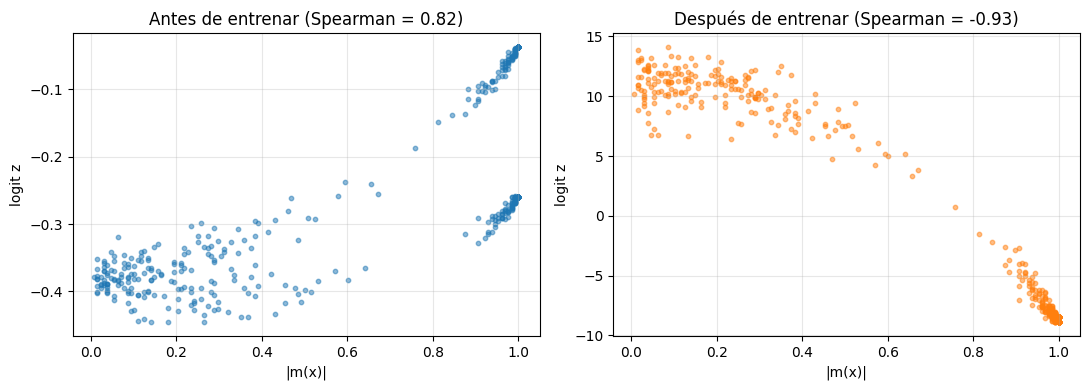

Spearman antes de entrenar:   0.815
Spearman después de entrenar: -0.926


In [87]:
# |m| de cada configuración de test (promedio de los espines)
m_abs = np.abs(X_test.mean(axis=(1, 2, 3)))

# Logit a partir de la probabilidad: z = log(p / (1 - p))
def logit(modelo, X_):
    p = modelo.predict(X_, verbose=0).ravel()
    p = np.clip(p, 1e-7, 1 - 1e-7)          # evita log(0); satura en ±16
    return np.log(p / (1 - p))

# Modelo ya entrenado
z_entrenado = logit(model, X_test)

# Misma arquitectura, pero sin entrenar (pesos aleatorios)
keras.utils.set_random_seed(1234)
model_random = keras.Sequential([
    keras.Input(shape=(None, None, 1)),
    layers.Conv2D(8, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
z_random = logit(model_random, X_test)

# Correlación de Spearman entre |m| y el logit (mide si la relación es monótona)
c_random = pd.Series(m_abs).corr(pd.Series(z_random), method="spearman")
c_entrenado = pd.Series(m_abs).corr(pd.Series(z_entrenado), method="spearman")

# Gráficas lado a lado
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].scatter(m_abs, z_random, s=10, alpha=0.5)
axs[0].set_title(f"Antes de entrenar (Spearman = {c_random:.2f})")
axs[1].scatter(m_abs, z_entrenado, s=10, alpha=0.5, color="C1")
axs[1].set_title(f"Después de entrenar (Spearman = {c_entrenado:.2f})")
for ax in axs:
    ax.set_xlabel("|m(x)|")
    ax.set_ylabel("logit z")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Spearman antes de entrenar:   {c_random:.3f}")
print(f"Spearman después de entrenar: {c_entrenado:.3f}")

### Conclusión: logit vs. |m(x)|

Después de entrenar, el logit es una función claramente decreciente de |m(x)| (Spearman = −0.926): las configuraciones con |m| cercano a 1 (ordenadas) tienen logits muy negativos, y las de |m| cercano a 0 (desordenadas) tienen logits positivos. El logit entrenado cubre un rango amplio (de −8.9 a +14.2), así que la red clasifica con mucha seguridad. Esto indica que usa la magnetización, o algo muy parecido, como señal principal para decidir la fase.

Antes de entrenar, el logit ya muestra una relación fuerte con |m| (Spearman = +0.815), pero con el signo opuesto y en un rango minúsculo (de −0.45 a −0.04, es decir, probabilidades cercanas a 0.5). Esto indica que la arquitectura, sobre todo `GlobalAveragePooling2D`, que promedia los mapas sobre toda la red de forma parecida a M = (1/N)·Σsᵢ, ya hace que la salida dependa de |m| aunque los pesos sean aleatorios. Lo que no tiene el modelo sin entrenar es la dirección correcta (que decide la inicialización) ni la magnitud necesaria para clasificar.

Por lo tanto, no diría que la red "redescubrió" el parámetro de orden desde cero, ni que todo se debe a la arquitectura. La arquitectura aporta la dependencia con |m|, y el entrenamiento la invierte en el sentido físico correcto (más orden, menos probabilidad de fase desordenada) y la amplifica enormemente. Esto coincide con los resultados anteriores: los filtros 0, 1, 3 y 7 se parecían a un promedio local.

La relación no es perfecta (|ρ| = 0.926 < 1), así que a un mismo |m| el logit puede variar. La red probablemente usa también información extra como bornes y no solo se enfoque en magnetizacion !